# Name : Shubh Veerwani
# Class : B
# Batch : B3
# Roll no. : 34

# LAB 5 – K-Nearest Neighbours (KNN) 

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, GridSearchCV, cross_val_score, StratifiedKFold)
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score)

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

## 2. Load Data & Basic Inspection

In [2]:
df = pd.read_csv("diabetes.csv")

In [3]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [5]:
df.shape

(768, 9)

In [6]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [8]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [9]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [10]:
df.duplicated().sum()

0

**Observation:** There are no `NaN` values and no duplicate rows. However, columns like `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` and `BMI` cannot be 0 for a living person – these zeros are hidden missing values that we will fix in the cleaning step.

# EDA – Exploratory Data Analysis

## 3. Univariate Analysis

### 3.1 Target variable distribution

Outcome
0    500
1    268
Name: count, dtype: int64

Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64


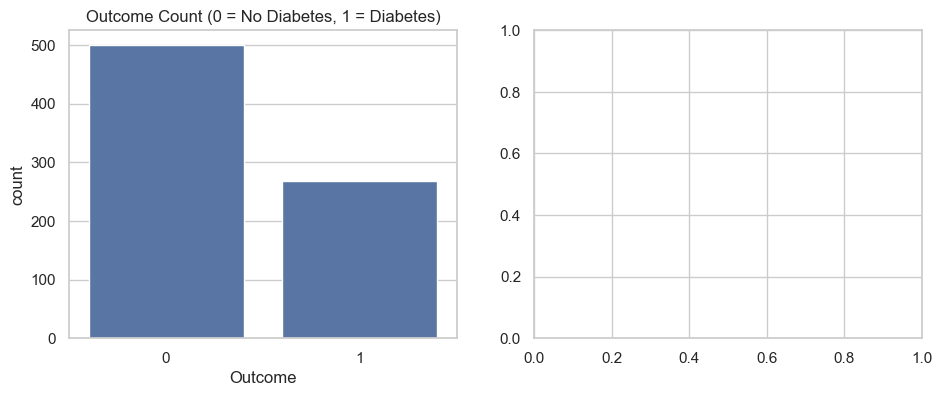

In [59]:
print(df["Outcome"].value_counts())
print()
print(df["Outcome"].value_counts(normalize=True).round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="Outcome", data=df, ax=ax[0])
ax[0].set_title("Outcome Count (0 = No Diabetes, 1 = Diabetes)")


plt.tight_layout()
plt.show()

**Observation:** The data is moderately imbalanced (~65 % non-diabetic vs ~35 % diabetic), so we use `stratify=y` when splitting and look at recall/F1 and not only accuracy.

### 3.2 Histogram + KDE of every feature

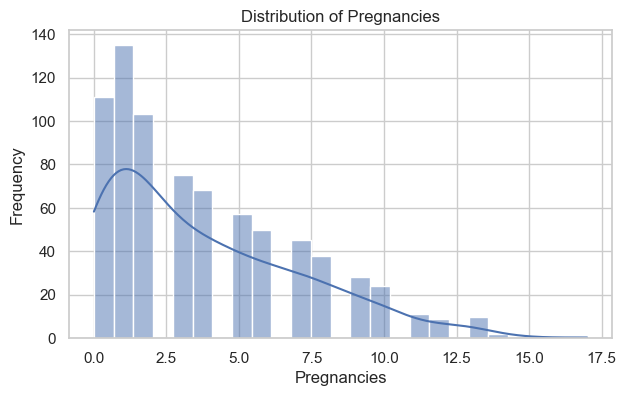

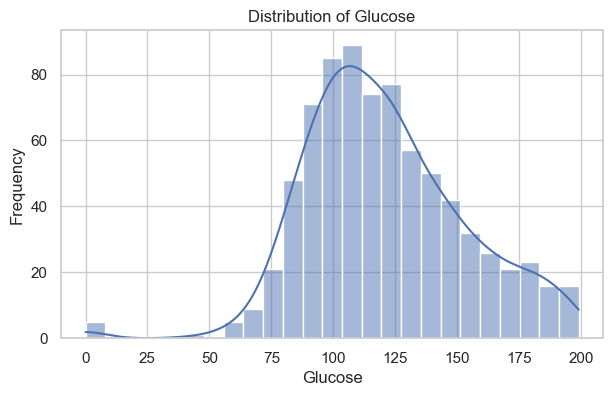

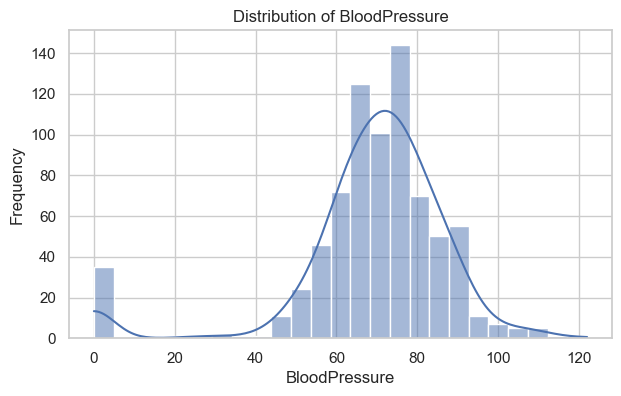

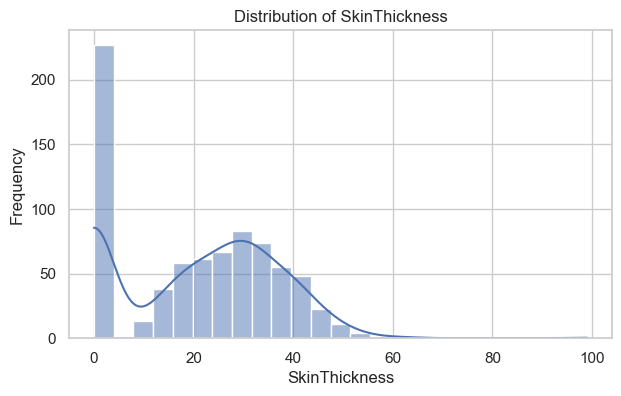

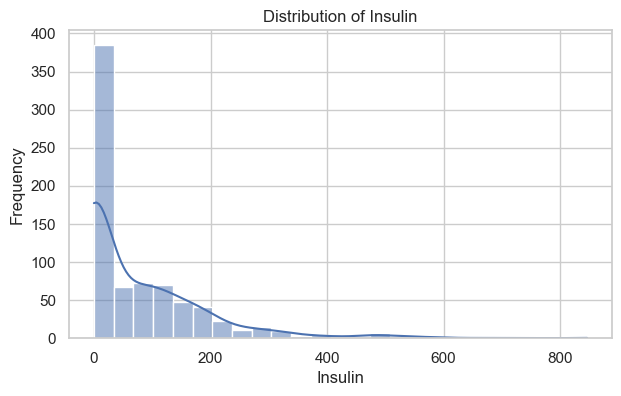

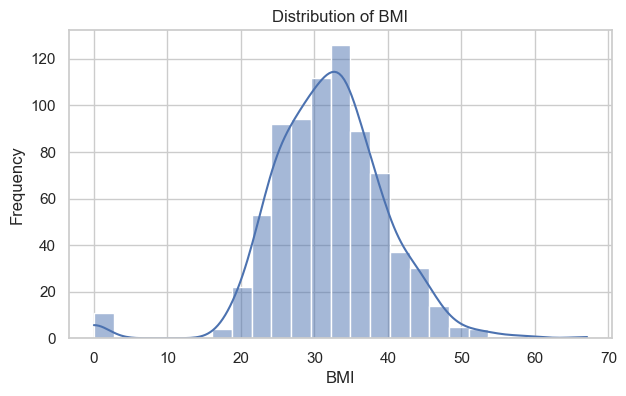

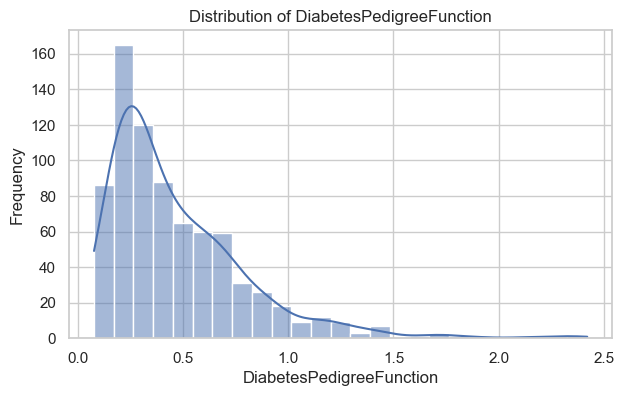

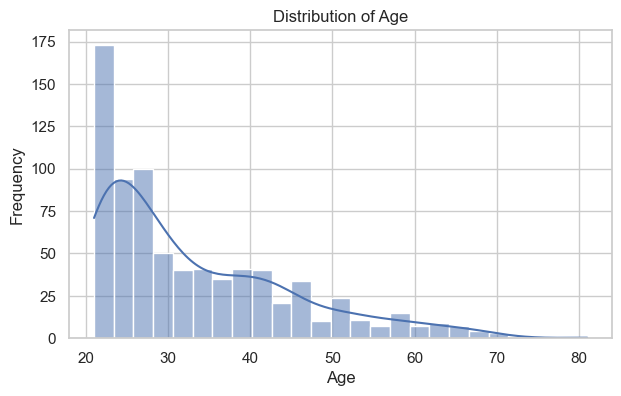

In [12]:
feature_cols = df.drop(columns="Outcome").columns

for col in feature_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col], kde=True, bins=25)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

### 3.3 Boxplots – outlier analysis

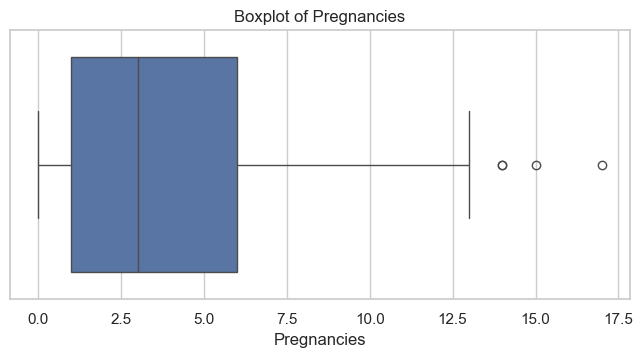

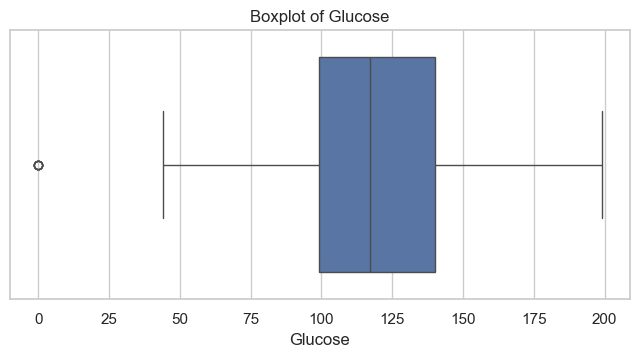

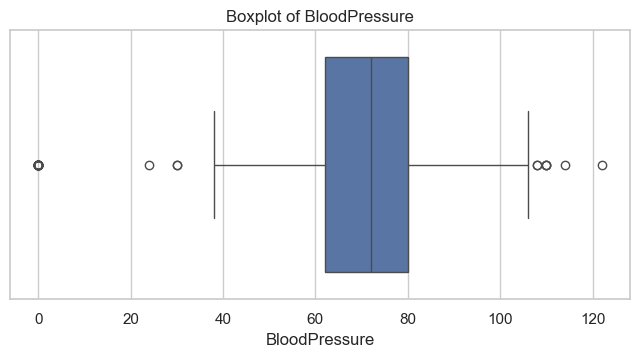

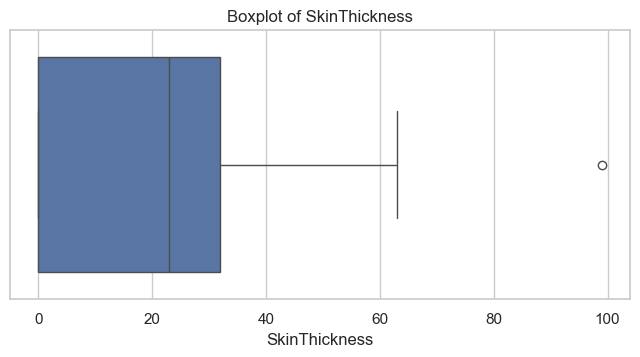

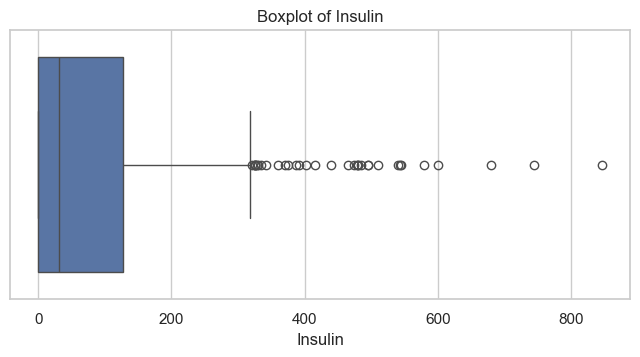

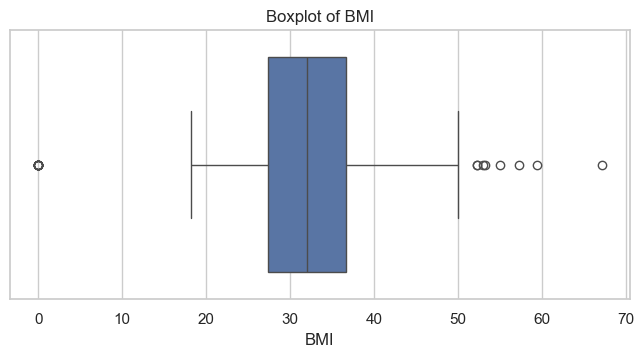

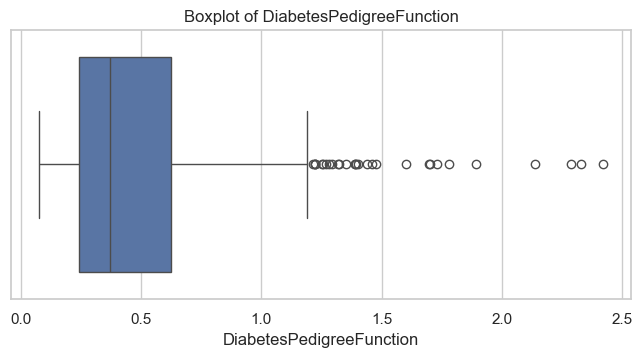

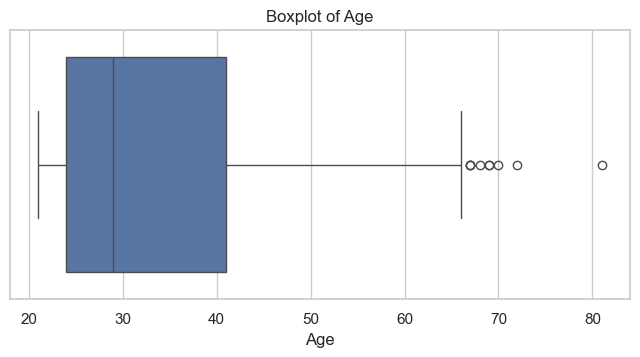

In [13]:
for col in feature_cols:
    plt.figure(figsize=(8, 3.5))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

### 3.4 Outlier detection using the IQR method

In [14]:
features = df.drop(columns="Outcome")

Q1 = features.quantile(0.25)
Q3 = features.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (features < lower_bound) | (features > upper_bound)
outlier_count = outlier_mask.sum()
outlier_percentage = (outlier_count / len(features)) * 100

outlier_summary = pd.DataFrame({
    "Q1": Q1, "Q3": Q3, "IQR": IQR,
    "lower bound": lower_bound, "upper bound": upper_bound,
    "Outlier Count": outlier_count, "Outlier %": outlier_percentage
})
outlier_summary.round(3)

,Q1,Q3,IQR,lower bound,upper bound,Outlier Count,Outlier %
Pregnancies,1.000,6.000,5.000,-6.500,13.500,4,0.521
Glucose,99.000,140.250,41.250,37.125,202.125,5,0.651
BloodPressure,62.000,80.000,18.000,35.000,107.000,45,5.859
SkinThickness,0.000,32.000,32.000,-48.000,80.000,1,0.130
Insulin,0.000,127.250,127.250,-190.875,318.125,34,4.427
BMI,27.300,36.600,9.300,13.350,50.550,19,2.474
DiabetesPedigreeFunction,0.244,0.626,0.382,-0.330,1.200,29,3.776
Age,24.000,41.000,17.000,-1.500,66.500,9,1.172


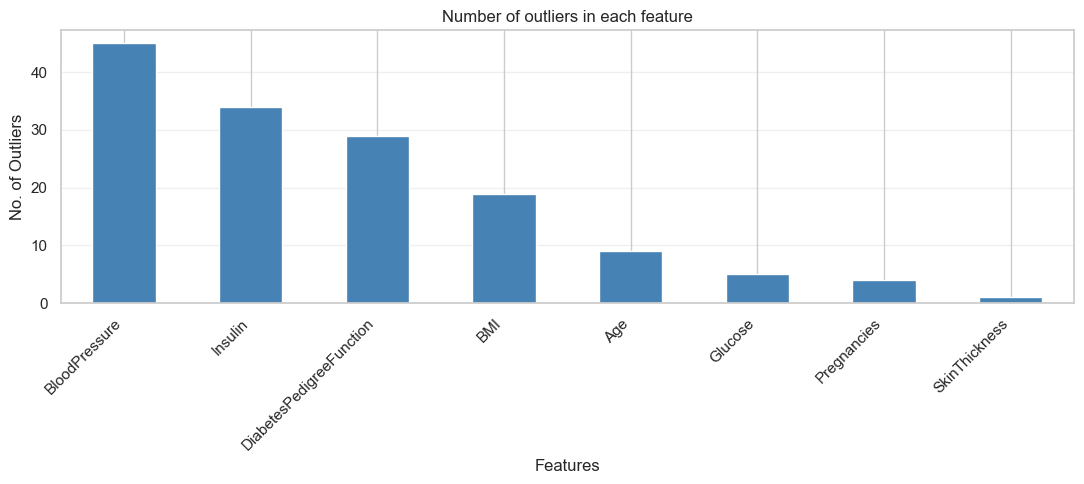

In [15]:
plt.figure(figsize=(11, 5))
outlier_count.sort_values(ascending=False).plot(kind="bar", color="steelblue")
plt.title("Number of outliers in each feature")
plt.xlabel("Features")
plt.ylabel("No. of Outliers")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 3.5 Invalid zero values (hidden missing data)

               Zero count  Zero %
Glucose                 5    0.65
BloodPressure          35    4.56
SkinThickness         227   29.56
Insulin               374   48.70
BMI                    11    1.43


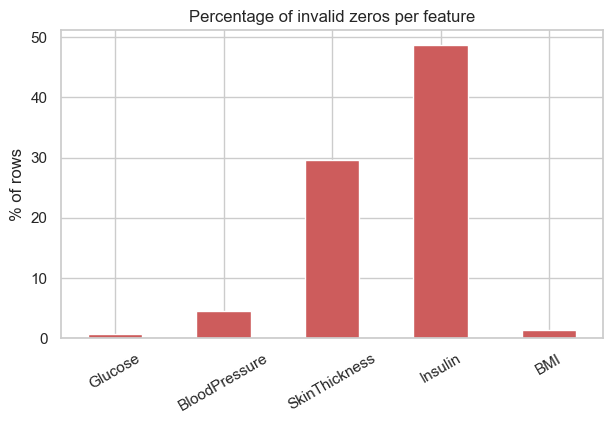

In [16]:
zero_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

zero_counts = (df[zero_columns] == 0).sum()
zero_pct = (zero_counts / len(df) * 100).round(2)
print(pd.DataFrame({"Zero count": zero_counts, "Zero %": zero_pct}))

plt.figure(figsize=(7, 4))
zero_pct.plot(kind="bar", color="indianred")
plt.title("Percentage of invalid zeros per feature")
plt.ylabel("% of rows")
plt.xticks(rotation=30)
plt.show()

**Observation:** `Insulin` (~49 %) and `SkinThickness` (~30 %) have a very large share of zeros, so these are treated as missing values and imputed.

## 4. Bivariate Analysis

### 4.1 Each feature vs Outcome (boxplots)

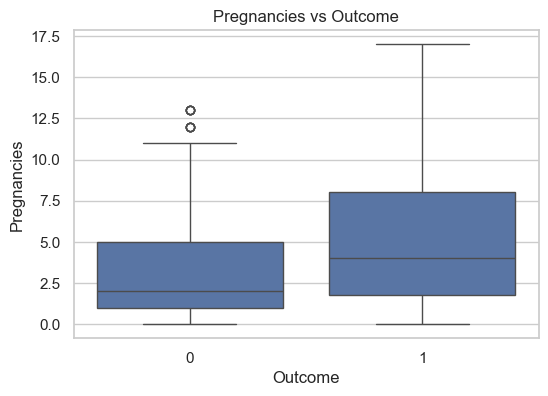

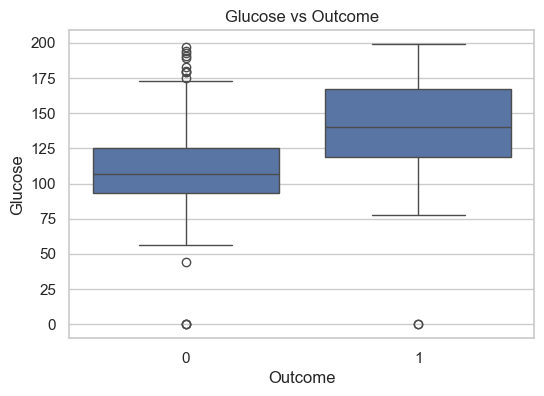

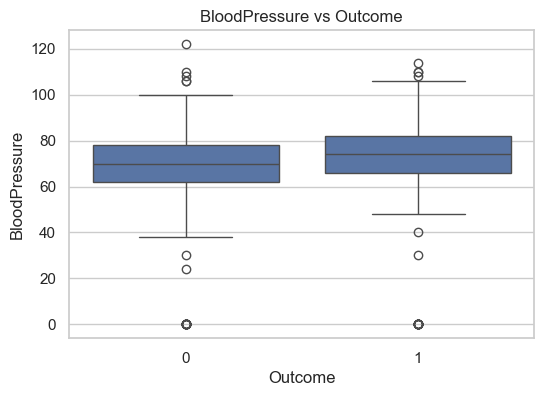

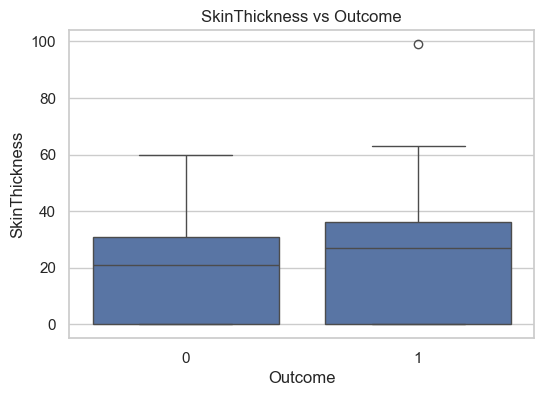

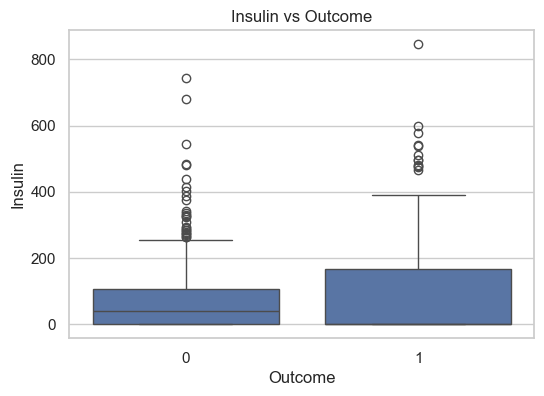

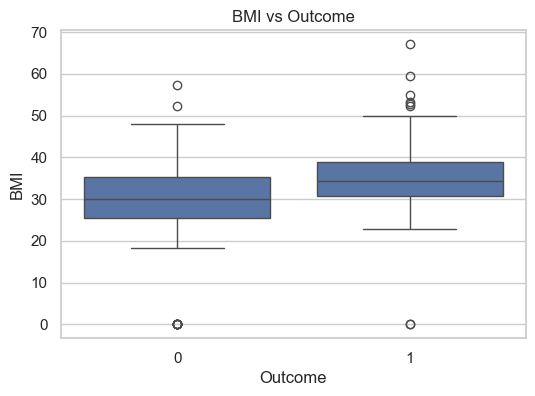

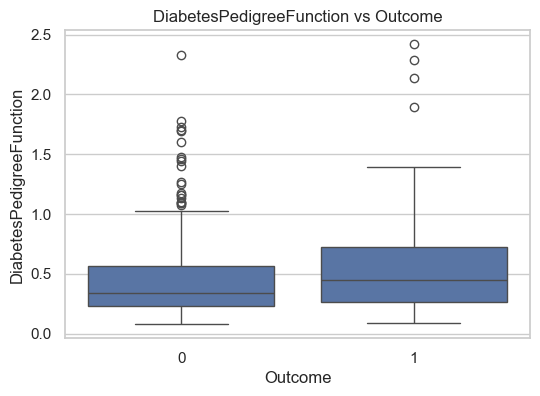

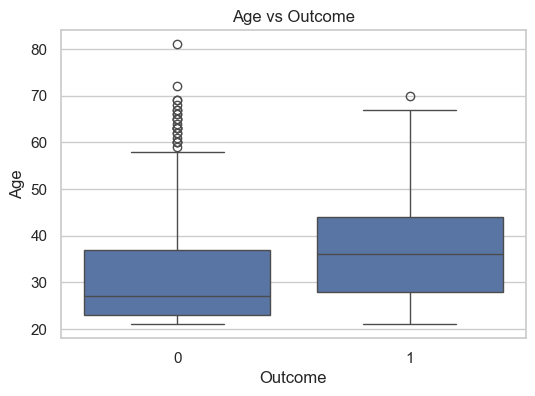

In [17]:
for col in feature_cols:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x="Outcome", y=col, data=df)
    plt.title(f"{col} vs Outcome")
    plt.show()

### 4.2 Mean of every feature by Outcome

In [18]:
df.groupby("Outcome")[list(feature_cols)].mean().round(2).T

Outcome,0,1
Pregnancies,3.30,4.87
Glucose,109.98,141.26
BloodPressure,68.18,70.82
SkinThickness,19.66,22.16
Insulin,68.79,100.34
BMI,30.30,35.14
DiabetesPedigreeFunction,0.43,0.55
Age,31.19,37.07


### 4.3 Scatter plots of key features

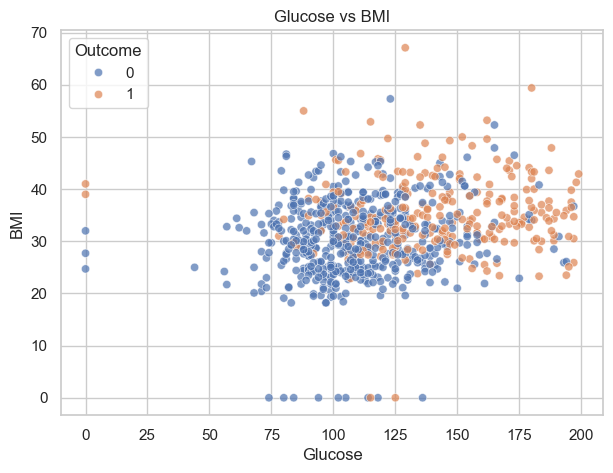

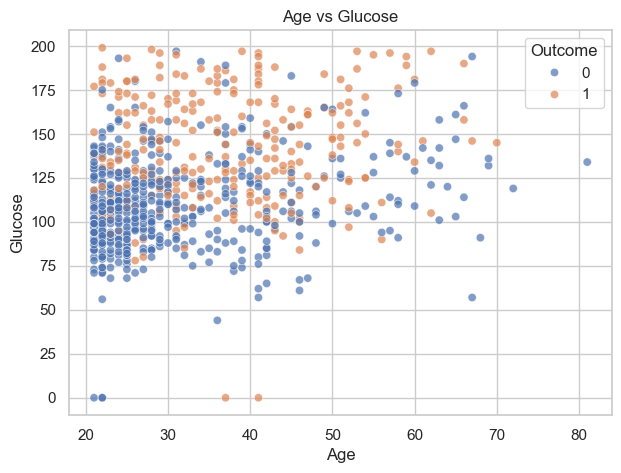

In [19]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x="Glucose", y="BMI", hue="Outcome", data=df, alpha=0.7)
plt.title("Glucose vs BMI")
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(x="Age", y="Glucose", hue="Outcome", data=df, alpha=0.7)
plt.title("Age vs Glucose")
plt.show()

### 4.4 Diabetes rate by age group

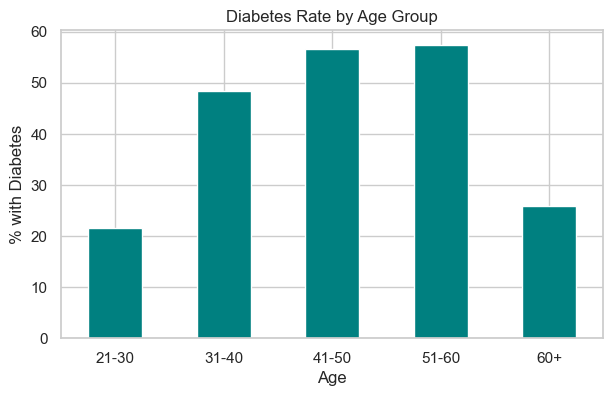

In [20]:
age_group = pd.cut(df["Age"], bins=[20, 30, 40, 50, 60, 100], labels=["21-30", "31-40", "41-50", "51-60", "60+"])
rate = df.groupby(age_group)["Outcome"].mean() * 100

plt.figure(figsize=(7, 4))
rate.plot(kind="bar", color="teal")
plt.ylabel("% with Diabetes")
plt.title("Diabetes Rate by Age Group")
plt.xticks(rotation=0)
plt.show()

## 5. Multivariate Analysis

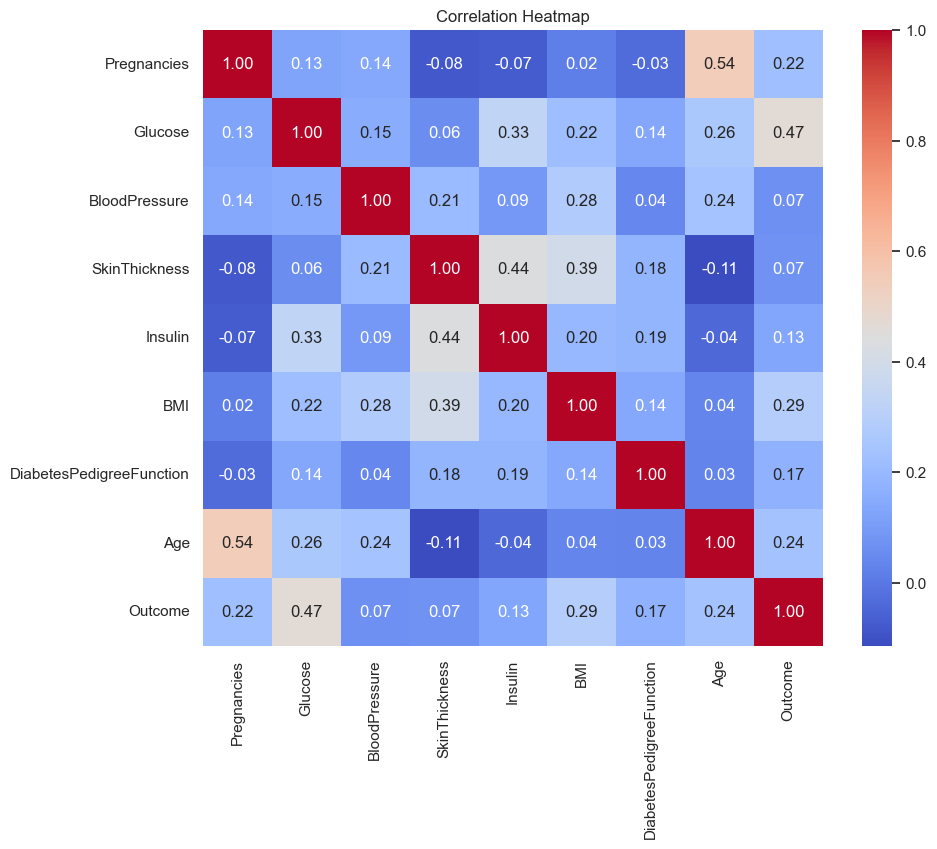

In [21]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [22]:
corr_target = df.corr(numeric_only=True)["Outcome"].drop("Outcome").sort_values(ascending=False)
print("Correlation of each feature with Outcome:\n")
print(corr_target.round(3))

Correlation of each feature with Outcome:

Glucose                     0.467
BMI                         0.293
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
Insulin                     0.131
SkinThickness               0.075
BloodPressure               0.065
Name: Outcome, dtype: float64


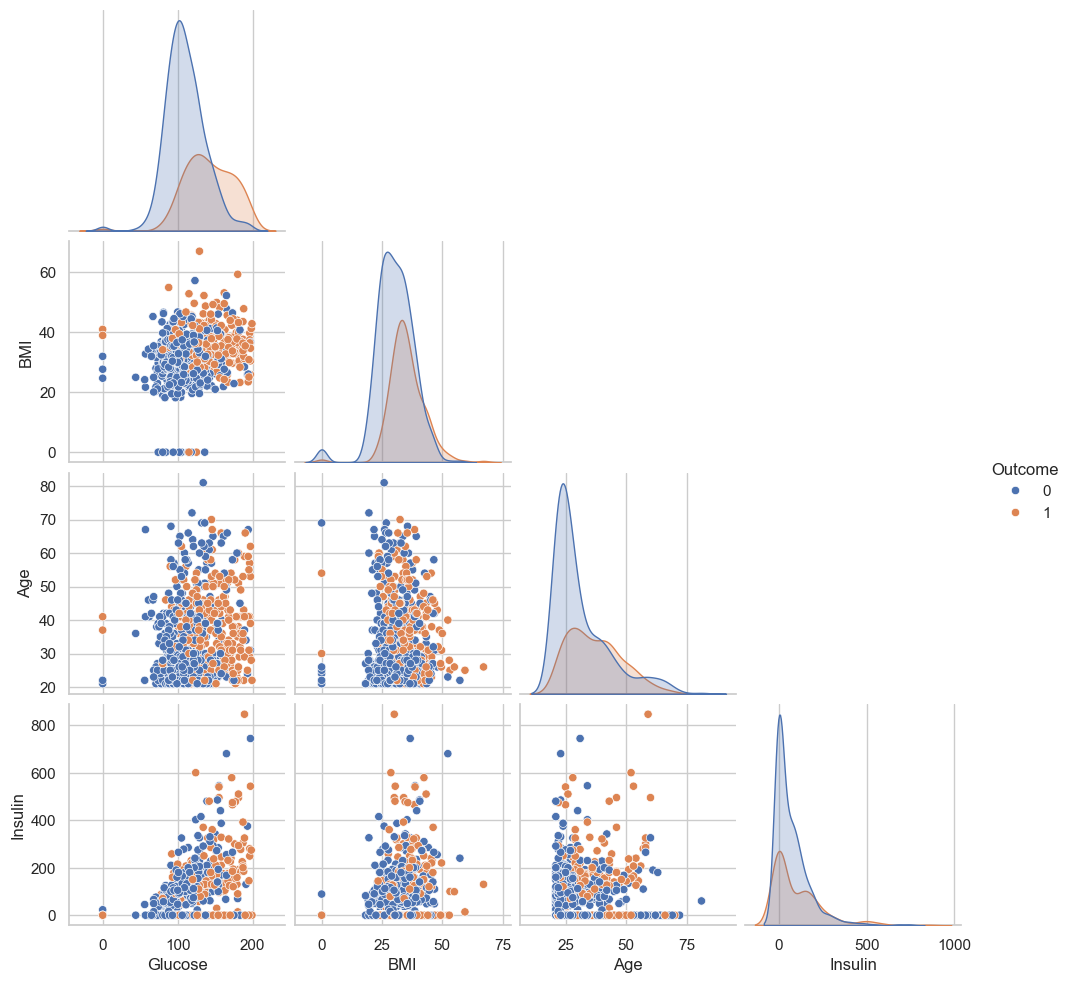

In [23]:
selected = ["Glucose", "BMI", "Age", "Insulin", "Outcome"]
sns.pairplot(df[selected], hue="Outcome", diag_kind="kde", corner=True)
plt.show()

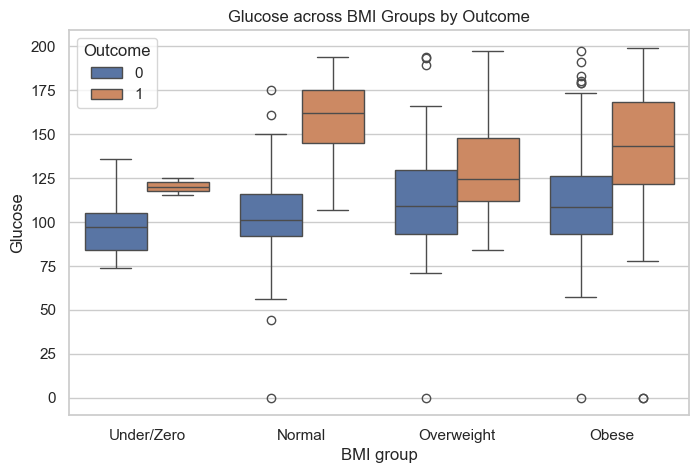

In [24]:
# Multivariate: Glucose across BMI groups, split by Outcome
bmi_group = pd.cut(df["BMI"], bins=[-1, 18.5, 25, 30, 100], labels=["Under/Zero", "Normal", "Overweight", "Obese"])
plt.figure(figsize=(8, 5))
sns.boxplot(x=bmi_group, y="Glucose", hue="Outcome", data=df)
plt.title("Glucose across BMI Groups by Outcome")
plt.xlabel("BMI group")
plt.show()

**EDA Summary**
- `Glucose` has the strongest correlation with `Outcome`, followed by `BMI`, `Age` and `Pregnancies`.
- Diabetic patients tend to have higher glucose, BMI and age.
- Features are on very different scales (`Insulin` up to ~850 vs `DiabetesPedigreeFunction` < 3) → **scaling is mandatory for KNN**, which is distance based.
- Several features contain invalid zeros → they must be imputed before modelling.

## 6. Data Cleaning – Replace Invalid Zeros

In [25]:
df_clean = df.copy()
df_clean[zero_columns] = df_clean[zero_columns].replace(0, np.nan)
print("Missing values after replacing invalid zeroes")
print(df_clean.isnull().sum())

Missing values after replacing invalid zeroes
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [26]:
for col in zero_columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("Missing values after median imputation: ")
print(df_clean.isnull().sum())

Missing values after median imputation: 
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


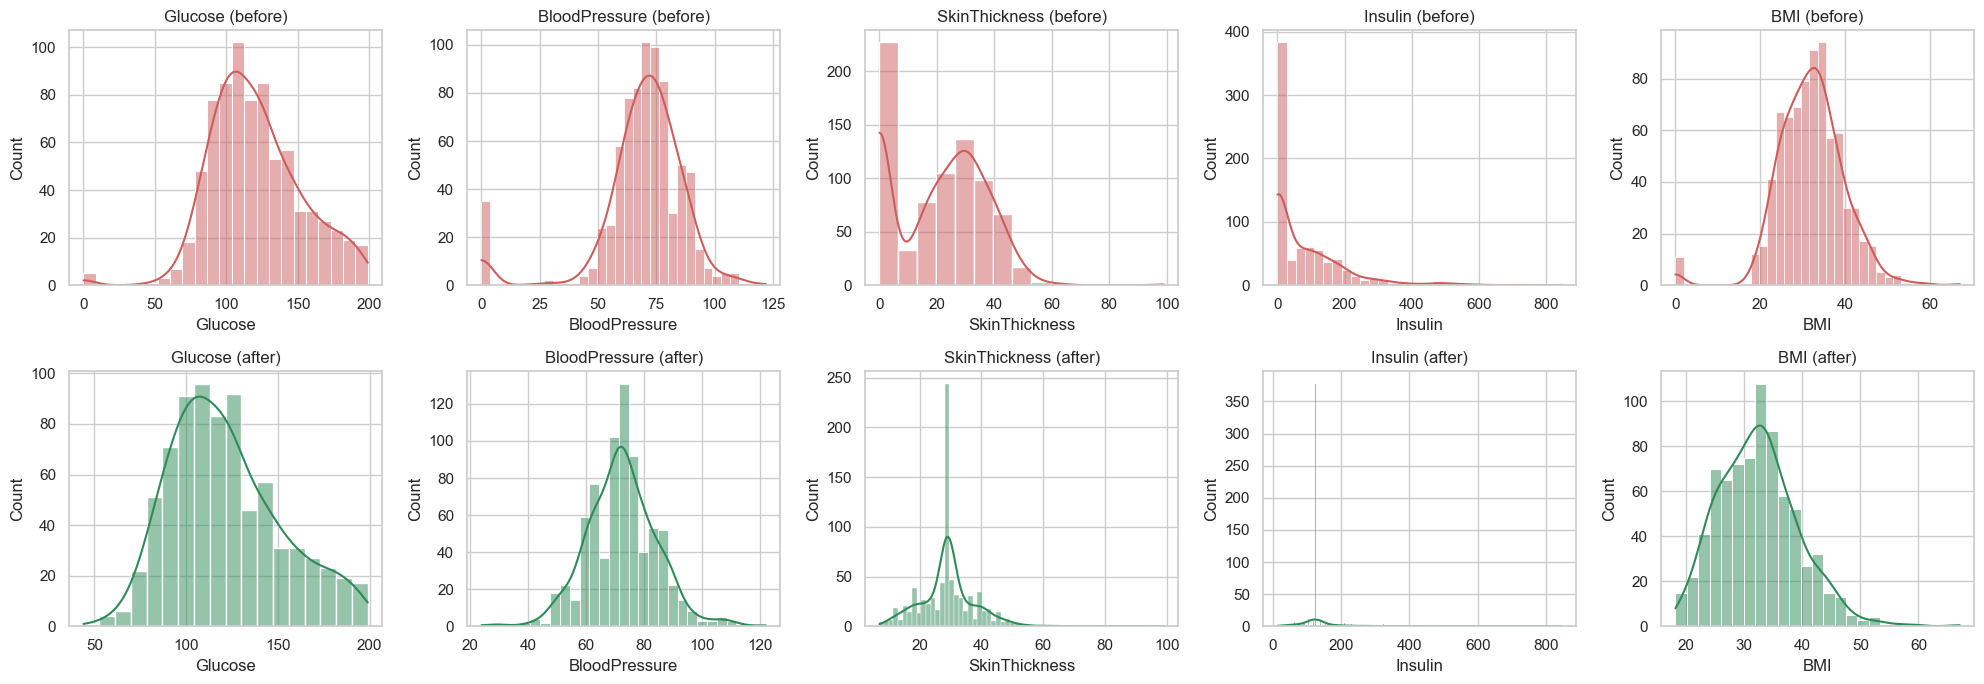

In [27]:
# Compare distributions before / after cleaning
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for i, col in enumerate(zero_columns):
    sns.histplot(df[col], kde=True, ax=axes[0, i], color="indianred")
    axes[0, i].set_title(f"{col} (before)")
    sns.histplot(df_clean[col], kde=True, ax=axes[1, i], color="seagreen")
    axes[1, i].set_title(f"{col} (after)")
plt.tight_layout()
plt.show()

## 7. Features / Target, Train–Test Split

In [28]:
X = df_clean.drop("Outcome", axis=1)
y = df_clean["Outcome"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (768, 8)
y shape: (768,)


In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 614
Testing samples: 154


In [30]:
print("Training Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True))

Training Distribution:
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64

Testing distribution:
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


## 8. Feature Scaling (StandardScaler)

> **Important:** the scaler is **fitted on the training data only** and then used to *transform* the test data. Calling `fit_transform` on `X_test` would leak test information (data leakage), so that step has been removed.

In [31]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [32]:
comparison = pd.DataFrame({
    "Original Mean": X_train.mean(),
    "Original Std": X_train.std(),
    "Scaled Mean": X_train_scaled.mean(axis=0),
    "Scaled Std": X_train_scaled.std(axis=0)
})
comparison.round(3)

,Original Mean,Original Std,Scaled Mean,Scaled Std
Pregnancies,3.819,3.314,-0.0,1.0
Glucose,121.671,30.004,-0.0,1.0
BloodPressure,72.140,12.275,0.0,1.0
SkinThickness,29.042,8.892,-0.0,1.0
Insulin,137.705,78.765,-0.0,1.0
BMI,32.447,6.824,-0.0,1.0
DiabetesPedigreeFunction,0.477,0.330,-0.0,1.0
Age,33.366,11.833,-0.0,1.0


## 9. KNN Model (K = 5)

In [33]:
k = 5
knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [34]:
y_pred = knn.predict(X_test_scaled)
print("Predictions:")
print(y_pred[:20])

Predictions:
[1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 1 1 0 1 0]


In [35]:
y_prob = knn.predict_proba(X_test_scaled)[:, 1]
print(y_prob[:20])

[0.6 0.2 0.2 0.6 0.  0.2 0.2 0.8 0.  0.6 0.4 0.6 0.  0.  0.  0.6 0.8 0.
 1.  0.2]


### 9.1 Evaluation metrics

In [36]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 score : {f1:.4f}")

Accuracy : 0.7532
Precision: 0.6600
Recall   : 0.6111
F1 score : 0.6346


In [37]:
print(classification_report(y_test, y_pred, target_names=["No Diabetes", "Diabetes"]))

              precision    recall  f1-score   support

 No Diabetes       0.80      0.83      0.81       100
    Diabetes       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



In [38]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[83 17]
 [21 33]]


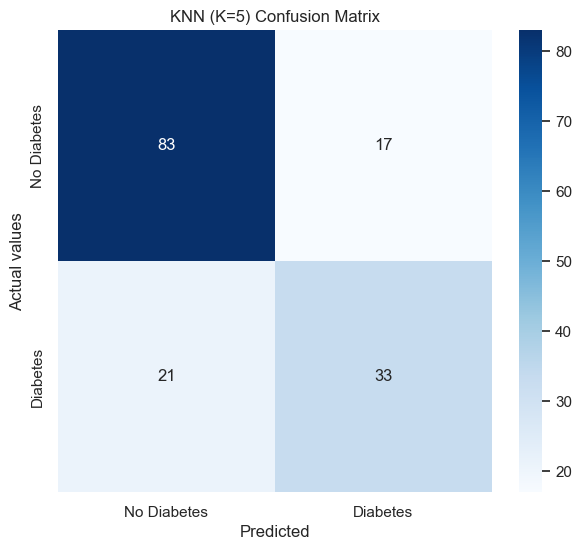

In [39]:
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Diabetes", "Diabetes"],
            yticklabels=["No Diabetes", "Diabetes"])
plt.xlabel("Predicted")
plt.ylabel("Actual values")
plt.title("KNN (K=5) Confusion Matrix")
plt.show()

In [40]:
train_acc_k5 = knn.score(X_train_scaled, y_train)
test_acc_k5 = knn.score(X_test_scaled, y_test)
print(f"Training accuracy: {train_acc_k5:.4f}")
print(f"Testing accuracy : {test_acc_k5:.4f}")

Training accuracy: 0.8306
Testing accuracy : 0.7532


## 10. Choosing the Best K

### 10.1 Train vs Test accuracy for K = 1 … 30

In [41]:
k_values = range(1, 31)
train_accuracy, test_accuracy = [], []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    train_accuracy.append(model.score(X_train_scaled, y_train))
    test_accuracy.append(model.score(X_test_scaled, y_test))

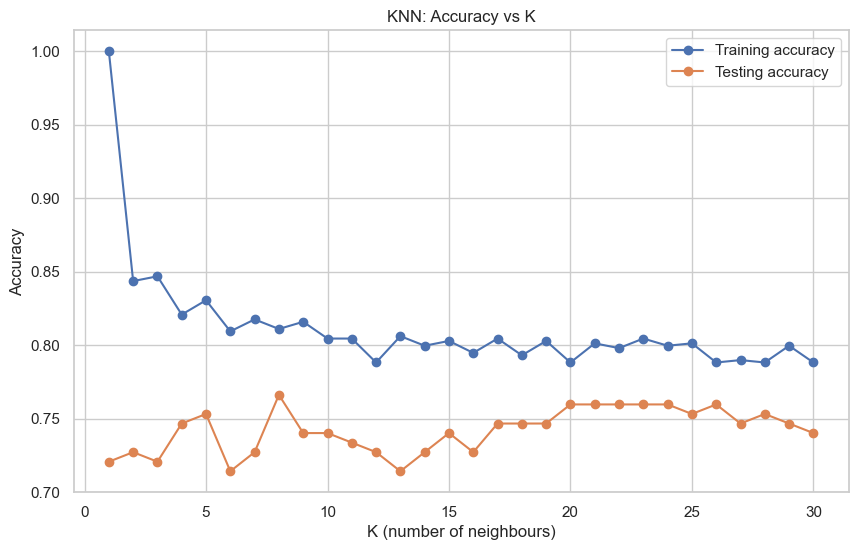

In [42]:
plt.figure(figsize=(10, 6))
plt.plot(k_values, train_accuracy, marker="o", label="Training accuracy")
plt.plot(k_values, test_accuracy, marker="o", label="Testing accuracy")
plt.xlabel("K (number of neighbours)")
plt.ylabel("Accuracy")
plt.title("KNN: Accuracy vs K")
plt.legend()
plt.show()

In [43]:
best_k_accuracy = k_values[np.argmax(test_accuracy)]
print("Best K:", best_k_accuracy)
print("Best Accuracy:", max(test_accuracy))

Best K: 8
Best Accuracy: 0.7662337662337663


**Observation:** For very small K (e.g. K = 1) the training accuracy is ~100 % but the test accuracy is lower → **overfitting** (low bias, high variance). As K grows the gap closes; if K becomes too large the model **underfits**.

### 10.2 10-fold Stratified Cross-Validation (on training data)

In [44]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
cv_scores = []
for k in range(1, 31):
    model = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(model, X_train_scaled, y_train, cv=cv, scoring="accuracy")
    cv_scores.append(scores.mean())

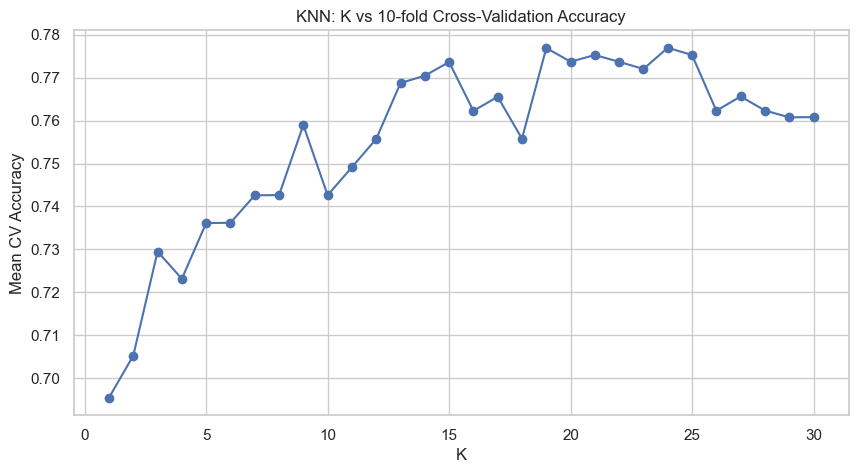

In [45]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, 31), cv_scores, marker="o")
plt.xlabel("K")
plt.ylabel("Mean CV Accuracy")
plt.title("KNN: K vs 10-fold Cross-Validation Accuracy")
plt.show()

In [46]:
best_k_cv = np.argmax(cv_scores) + 1
print("Best K based on cross validation:", best_k_cv)
print("Best CV Accuracy:", max(cv_scores))

Best K based on cross validation: 24
Best CV Accuracy: 0.776969857218403


## 11. Hyper-parameter Tuning – GridSearchCV

In [47]:
param_grid = {
    "n_neighbors": list(range(3, 31, 2)),
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"]
}
grid_search = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)
grid_search.fit(X_train_scaled, y_train)

GridSearchCV(cv=5, estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid={'metric': ['euclidean', 'manhattan'],
                         'n_neighbors': [3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23,
                                         25, 27, 29],
                         'weights': ['uniform', 'distance']},
             scoring='accuracy')

In [48]:
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)

Best Parameters: {'metric': 'euclidean', 'n_neighbors': 19, 'weights': 'uniform'}
Best Cross-Validation Accuracy: 0.7769025723044115


In [49]:
# Top 5 parameter combinations
results = pd.DataFrame(grid_search.cv_results_)
results[["param_n_neighbors", "param_weights", "param_metric", "mean_test_score", "rank_test_score"]] \
    .sort_values("rank_test_score").head(5)

,param_n_neighbors,param_weights,param_metric,mean_test_score,rank_test_score
16,19,uniform,euclidean,0.776903,1
45,19,distance,manhattan,0.775250,2
17,19,distance,euclidean,0.773651,3
18,21,uniform,euclidean,0.773637,4
44,19,uniform,manhattan,0.773611,5


## 12. Final (Tuned) Model Evaluation

In [50]:
best_knn = grid_search.best_estimator_
y_pred_best = best_knn.predict(X_test_scaled)
y_prob_best = best_knn.predict_proba(X_test_scaled)[:, 1]

print("Tuned KNN - Test results")
print(f"Accuracy : {accuracy_score(y_test, y_pred_best):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_best):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_best):.4f}")
print(f"F1 score : {f1_score(y_test, y_pred_best):.4f}")
print()
print(classification_report(y_test, y_pred_best, target_names=["No Diabetes", "Diabetes"]))

Tuned KNN - Test results
Accuracy : 0.7468
Precision: 0.6667
Recall   : 0.5556
F1 score : 0.6061

              precision    recall  f1-score   support

 No Diabetes       0.78      0.85      0.81       100
    Diabetes       0.67      0.56      0.61        54

    accuracy                           0.75       154
   macro avg       0.72      0.70      0.71       154
weighted avg       0.74      0.75      0.74       154



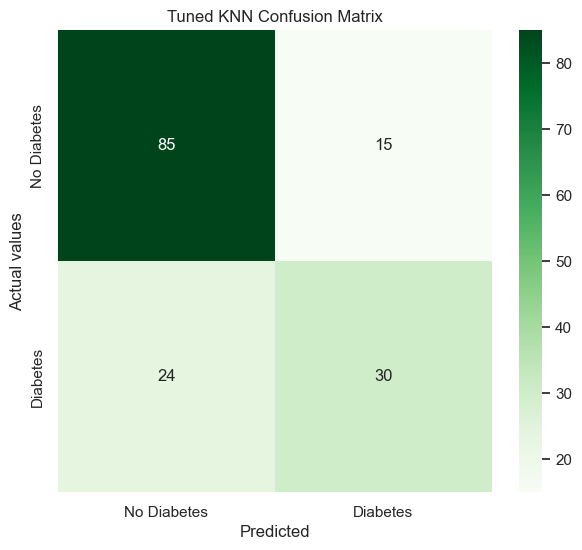

In [51]:
cm_best = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(7, 6))
sns.heatmap(cm_best, annot=True, fmt="d", cmap="Greens",
            xticklabels=["No Diabetes", "Diabetes"],
            yticklabels=["No Diabetes", "Diabetes"])
plt.xlabel("Predicted")
plt.ylabel("Actual values")
plt.title("Tuned KNN Confusion Matrix")
plt.show()

### 12.1 ROC Curve & AUC

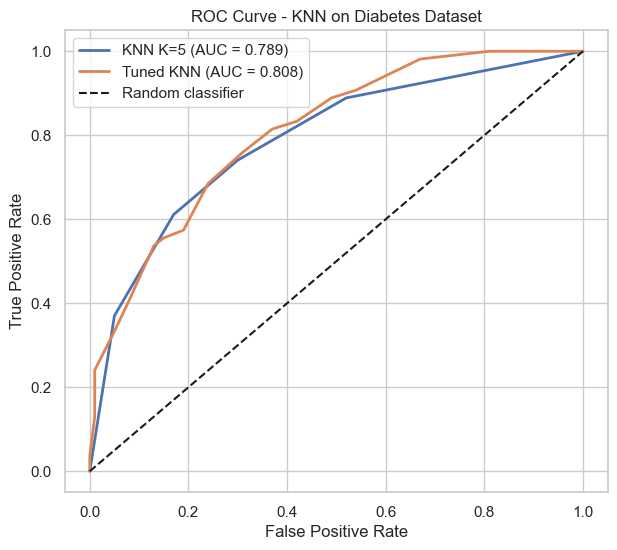

In [52]:
fpr_b, tpr_b, _ = roc_curve(y_test, y_prob)
fpr_t, tpr_t, _ = roc_curve(y_test, y_prob_best)
auc_base = roc_auc_score(y_test, y_prob)
auc_tuned = roc_auc_score(y_test, y_prob_best)

plt.figure(figsize=(7, 6))
plt.plot(fpr_b, tpr_b, linewidth=2, label=f"KNN K=5 (AUC = {auc_base:.3f})")
plt.plot(fpr_t, tpr_t, linewidth=2, label=f"Tuned KNN (AUC = {auc_tuned:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - KNN on Diabetes Dataset")
plt.legend()
plt.show()

### 12.2 Baseline vs Tuned comparison

In [53]:
final_comparison = pd.DataFrame({
    "Model": ["KNN (K=5)", "Tuned KNN"],
    "Accuracy": [accuracy_score(y_test, y_pred), accuracy_score(y_test, y_pred_best)],
    "Precision": [precision_score(y_test, y_pred), precision_score(y_test, y_pred_best)],
    "Recall": [recall_score(y_test, y_pred), recall_score(y_test, y_pred_best)],
    "F1 Score": [f1_score(y_test, y_pred), f1_score(y_test, y_pred_best)],
    "ROC-AUC": [auc_base, auc_tuned]
}).round(4)
final_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,KNN (K=5),0.7532,0.6600,0.6111,0.6346,0.7886
1,Tuned KNN,0.7468,0.6667,0.5556,0.6061,0.8077


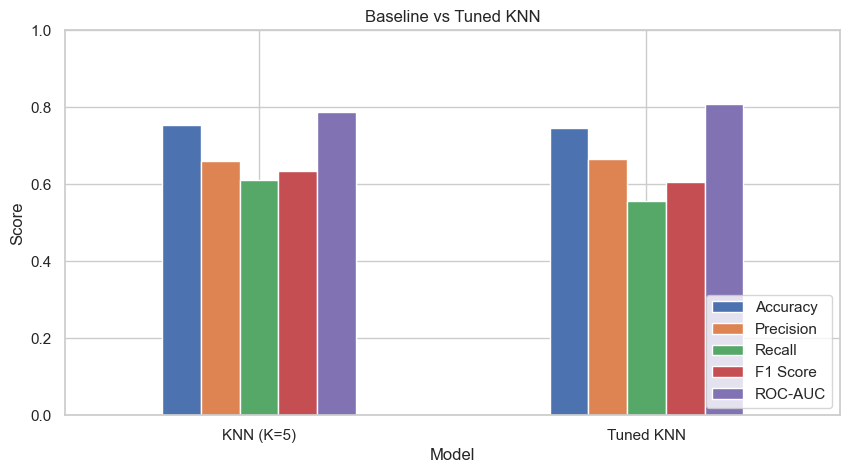

In [54]:
final_comparison.set_index("Model").plot(kind="bar", figsize=(10, 5))
plt.title("Baseline vs Tuned KNN")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.show()

## 13. Prediction on a New Patient

In [55]:
new_patient = pd.DataFrame([{
    "Pregnancies": 2,
    "Glucose": 150,
    "BloodPressure": 80,
    "SkinThickness": 30,
    "Insulin": 120,
    "BMI": 33.5,
    "DiabetesPedigreeFunction": 0.6,
    "Age": 45
}])[X.columns]

new_scaled = scaler.transform(new_patient)
pred = best_knn.predict(new_scaled)[0]
prob = best_knn.predict_proba(new_scaled)[0, 1]

print("Predicted class :", "Diabetes" if pred == 1 else "No Diabetes")
print(f"Probability of diabetes: {prob:.2f}")

Predicted class : Diabetes
Probability of diabetes: 0.63


## 14. Conclusion
- EDA showed that `Glucose`, `BMI`, `Age` and `Pregnancies` are the most informative features and that invalid zeros in five columns had to be treated as missing and imputed with the median.
- KNN is distance based, so features were standardised (scaler fitted on training data only, avoiding data leakage).
- Small K overfits, large K underfits; the best K was selected with the train/test curve, 10-fold cross-validation and finally `GridSearchCV` (K, weights, distance metric).
- The tuned model was evaluated using accuracy, precision, recall, F1, confusion matrix and ROC-AUC. Because the data is imbalanced, recall and F1 on the *Diabetes* class are important in addition to accuracy.